# Program 3

Obtain time-series stock-market data and perform analysis using Python by generating
candlestick charts, SMA and EMA overlays, rolling volatility bands, and volume trend
plots. Examine the data to identify trends, seasonal patterns, and significant changes
over time. Evaluate the visualizations to determine relationships among key variables,
variability, and long-term trends.

### 1. Load and Inspect the Dataset
Let's load the data from `/content/Dataset-NFLX.csv`, inspect its structure, and ensure the dates are parsed correctly.

In [ ]:
import pandas as pd

# Load the dataset
file_path = '/content/Dataset-NFLX.csv'
df = pd.read_csv(file_path)

# Standardize column names (strip whitespace and convert to Title Case)
df.columns = df.columns.str.strip().str.title()

# Convert Date to datetime and sort chronologically
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Display summary details and first few rows
print("Dataset Summary:")
display(df.info())
display(df.head())

Dataset Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4993 entries, 0 to 4992
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       4993 non-null   datetime64[ns]
 1   Open       4993 non-null   float64       
 2   High       4993 non-null   float64       
 3   Low        4993 non-null   float64       
 4   Close      4993 non-null   float64       
 5   Adj Close  4993 non-null   float64       
 6   Volume     4993 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 273.2 KB


/tmp/ipykernel_656/4124244650.py:11: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


None

,Date,Open,High,Low,Close,Adj Close,Volume
0,2002-05-23,1.156429,1.242857,1.145714,1.196429,1.196429,104790000
1,2002-05-24,1.214286,1.225000,1.197143,1.210000,1.210000,11104800
2,2002-05-28,1.213571,1.232143,1.157143,1.157143,1.157143,6609400
3,2002-05-29,1.164286,1.164286,1.085714,1.103571,1.103571,6757800
4,2002-05-30,1.107857,1.107857,1.071429,1.071429,1.071429,10154200


### 2. Calculate Indicators (SMA, EMA, Volatility Bands)
We will calculate the 20-day Simple Moving Average (SMA), 20-day Exponential Moving Average (EMA), and Bollinger Bands (20-day rolling mean ± 2 standard deviations).

In [ ]:
# Calculate 20-day SMA and EMA
df['SMA_20'] = df['Close'].rolling(window=20).mean()
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()

# Calculate Bollinger Bands (Rolling Volatility Bands)
rolling_std = df['Close'].rolling(window=20).std()
df['Bollinger_Upper'] = df['SMA_20'] + (rolling_std * 2)
df['Bollinger_Lower'] = df['SMA_20'] - (rolling_std * 2)

display(df[['Date', 'Close', 'SMA_20', 'EMA_20', 'Bollinger_Upper', 'Bollinger_Lower']].tail())

,Date,Close,SMA_20,EMA_20,Bollinger_Upper,Bollinger_Lower
4988,2022-03-16,357.529999,368.624501,368.740397,410.040968,327.208034
4989,2022-03-17,371.399994,367.290501,368.993692,406.364720,328.216282
4990,2022-03-18,380.600006,366.987001,370.099055,405.517944,328.456058
4991,2022-03-21,374.589996,366.152000,370.526764,403.159068,329.144933
4992,2022-03-22,382.920013,366.429001,371.707073,403.870317,328.987684


### 3. Generate Interactive Candlestick Chart, Overlays, and Volume
We'll use `plotly` to construct a dual-panel dashboard featuring the candlestick chart, indicators, and transaction volume.

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Create subplots: Row 1 = Candlestick & Indicators, Row 2 = Volume
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.08,
    subplot_titles=('Stock Price, Moving Averages & Volatility Bands', 'Volume Trend'),
    row_width=[0.3, 0.7]
)

# Row 1: Candlestick Chart
fig.add_trace(go.Candlestick(
    x=df['Date'], open=df['Open'], high=df['High'], low=df['Low'], close=df['Close'],
    name='Candlestick'
), row=1, col=1)

# Row 1: SMA Overlay
fig.add_trace(go.Scatter(
    x=df['Date'], y=df['SMA_20'], mode='lines', name='SMA 20',
    line=dict(color='orange', width=1.5)
), row=1, col=1)

# Row 1: EMA Overlay
fig.add_trace(go.Scatter(
    x=df['Date'], y=df['EMA_20'], mode='lines', name='EMA 20',
    line=dict(color='magenta', width=1.5)
), row=1, col=1)

# Row 1: Bollinger Upper Band
fig.add_trace(go.Scatter(
    x=df['Date'], y=df['Bollinger_Upper'], mode='lines', name='Bollinger Upper',
    line=dict(color='gray', width=1, dash='dash')
), row=1, col=1)

# Row 1: Bollinger Lower Band
fig.add_trace(go.Scatter(
    x=df['Date'], y=df['Bollinger_Lower'], mode='lines', name='Bollinger Lower',
    line=dict(color='gray', width=1, dash='dash'),
    fill='tonexty', fillcolor='rgba(128, 128, 128, 0.1)' # Fills the band region
), row=1, col=1)

# Row 2: Volume Bar Chart
# Color bars dynamically based on day performance (green for positive close, red for negative)
colors = ['green' if df['Close'].iloc[i] >= df['Open'].iloc[i] else 'red' for i in range(len(df))]
fig.add_trace(go.Bar(
    x=df['Date'], y=df['Volume'], name='Volume', marker_color=colors
), row=2, col=1)

# Update Layout
fig.update_layout(
    title_text='NFLX Stock Market Deep-Dive Analysis',
    xaxis_rangeslider_visible=False,
    height=800,
    template='plotly_dark'
)

fig.show()

### 4. Statistical Analysis of Trends & Seasonality
Let's aggregate the statistics by Year and Month to discover longer-term trends and seasonality patterns.

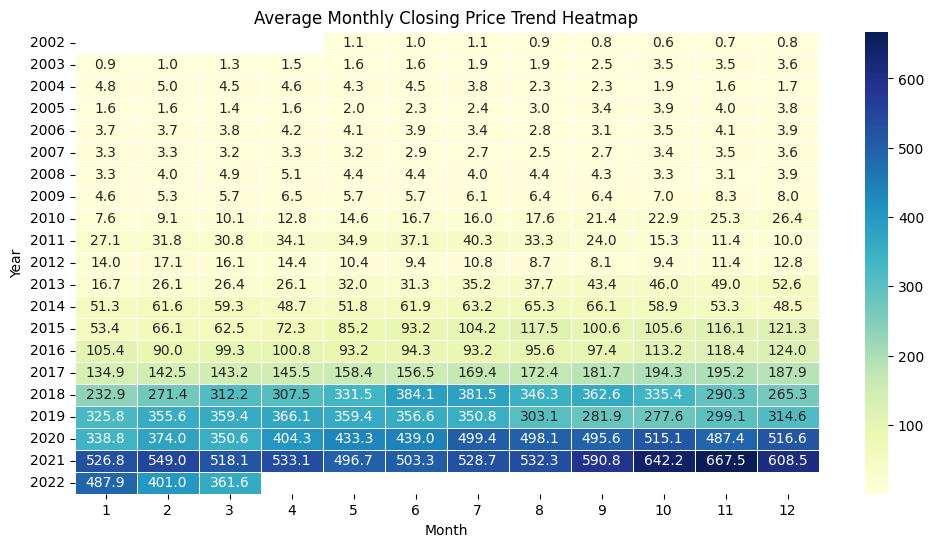

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

# Average Monthly Closing Price Heatmap (Seasonality Analysis)
pivot_table = df.pivot_table(values='Close', index='Year', columns='Month', aggfunc='mean')

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, cmap='YlGnBu', annot=True, fmt=".1f", linewidths=.5)
plt.title('Average Monthly Closing Price Trend Heatmap')
plt.xlabel('Month')
plt.ylabel('Year')
plt.show()

### 5. Separate Graphs
As requested, here are the technical indicators plotted as separate graphs instead of a single combined layout.

#### Graph 1: Candlestick Chart with SMA & EMA Overlays

In [ ]:
import plotly.graph_objects as go

# Graph 1: Candlestick with moving average overlays
fig_candle = go.Figure()

# Candlestick chart
fig_candle.add_trace(go.Candlestick(
    x=df['Date'], open=df['Open'], high=df['High'], low=df['Low'], close=df['Close'],
    name='Candlestick'
))

# SMA Overlay
fig_candle.add_trace(go.Scatter(
    x=df['Date'], y=df['SMA_20'], mode='lines', name='SMA 20',
    line=dict(color='orange', width=1.5)
))

# EMA Overlay
fig_candle.add_trace(go.Scatter(
    x=df['Date'], y=df['EMA_20'], mode='lines', name='EMA 20',
    line=dict(color='magenta', width=1.5)
))

fig_candle.update_layout(
    title='NFLX Candlestick Chart with SMA & EMA Overlays',
    xaxis_title='Date',
    yaxis_title='Price (USD)',
    xaxis_rangeslider_visible=True,
    template='plotly_dark',
    height=600
)

fig_candle.show()

#### Graph 2: Rolling Volatility Bands (Bollinger Bands)

In [ ]:
# Graph 2: Volatility Bands
fig_volatility = go.Figure()

# Closing price reference line
fig_volatility.add_trace(go.Scatter(
    x=df['Date'], y=df['Close'], mode='lines', name='Close Price',
    line=dict(color='white', width=1.5)
))

# Bollinger Upper Band
fig_volatility.add_trace(go.Scatter(
    x=df['Date'], y=df['Bollinger_Upper'], mode='lines', name='Bollinger Upper',
    line=dict(color='cyan', width=1, dash='dash')
))

# Bollinger Lower Band
fig_volatility.add_trace(go.Scatter(
    x=df['Date'], y=df['Bollinger_Lower'], mode='lines', name='Bollinger Lower',
    line=dict(color='cyan', width=1, dash='dash'),
    fill='tonexty', fillcolor='rgba(0, 255, 255, 0.05)'
))

fig_volatility.update_layout(
    title='NFLX Volatility Analysis (Bollinger Bands)',
    xaxis_title='Date',
    yaxis_title='Price (USD)',
    template='plotly_dark',
    height=500
)

fig_volatility.show()

#### Graph 3: Volume Trend Plot

In [ ]:
# Graph 3: Market Volume
fig_volume = go.Figure()

# Set colors dynamically based on price movement direction
colors = ['green' if df['Close'].iloc[i] >= df['Open'].iloc[i] else 'red' for i in range(len(df))]

fig_volume.add_trace(go.Bar(
    x=df['Date'], y=df['Volume'], name='Volume', marker_color=colors
))

fig_volume.update_layout(
    title='NFLX Daily Trading Volume Trend',
    xaxis_title='Date',
    yaxis_title='Volume',
    template='plotly_dark',
    height=450
)

fig_volume.show()

### 6. Dynamic Stock Analysis using `yfinance`
We will install `yfinance`, fetch historical NFLX stock data, compute the metrics, and display the charts as independent, standalone plots.

In [ ]:
!pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd
import plotly.graph_objects as go

# Download historical data for Netflix (NFLX)
# We'll fetch 5 years of daily data for a clean analysis
ticker = "NFLX"
yf_df = yf.download(ticker, period="5y", interval="1d")

# Reset index to make Date a column
yf_df = yf_df.reset_index()

# Ensure columns are 1D Series (flattening multi-level columns if any)
if isinstance(yf_df.columns, pd.MultiIndex):
    yf_df.columns = [col[0] if col[1] == '' else col[0] for col in yf_df.columns]

# Calculate technical indicators
yf_df['SMA_20'] = yf_df['Close'].rolling(window=20).mean()
yf_df['EMA_20'] = yf_df['Close'].ewm(span=20, adjust=False).mean()

rolling_std = yf_df['Close'].rolling(window=20).std()
yf_df['Bollinger_Upper'] = yf_df['SMA_20'] + (rolling_std * 2)
yf_df['Bollinger_Lower'] = yf_df['SMA_20'] - (rolling_std * 2)

display(yf_df.tail())

/tmp/ipykernel_656/803099956.py:8: FutureWarning:

YF.download() has changed argument auto_adjust default to True

[*********************100%***********************]  1 of 1 completed


,Date,Close,High,Low,Open,Volume,SMA_20,EMA_20,Bollinger_Upper,Bollinger_Lower
1249,2026-11-11,64.540001,64.559998,62.750000,62.840000,29564000,65.2515,65.330614,71.435181,59.067820
1250,2026-11-12,62.689999,64.300003,62.549999,64.269997,31558100,64.7555,65.079127,69.969317,59.541683
1251,2026-11-13,62.150002,63.950001,62.119999,62.880001,36667900,64.3365,64.800163,68.903108,59.769892
1252,2026-11-16,60.750000,62.980000,60.480000,62.889999,36078400,63.8815,64.414433,67.917649,59.845351
1253,2026-11-17,59.680000,61.009998,59.410000,60.560001,34876900,63.4310,63.963534,67.210495,59.651505


#### Graph 1: Standalone Candlestick Chart (with SMA & EMA Overlays)

In [ ]:
fig_candle = go.Figure()

fig_candle.add_trace(go.Candlestick(
    x=yf_df['Date'], open=yf_df['Open'], high=yf_df['High'], low=yf_df['Low'], close=yf_df['Close'],
    name='Candlestick'
))

fig_candle.add_trace(go.Scatter(
    x=yf_df['Date'], y=yf_df['SMA_20'], mode='lines', name='SMA 20',
    line=dict(color='orange', width=1.5)
))

fig_candle.add_trace(go.Scatter(
    x=yf_df['Date'], y=yf_df['EMA_20'], mode='lines', name='EMA 20',
    line=dict(color='magenta', width=1.5)
))

fig_candle.update_layout(
    title=f'{ticker} Interactive Candlestick Chart (with SMA & EMA Overlays)',
    xaxis_title='Date',
    yaxis_title='Price (USD)',
    template='plotly_dark',
    height=600
)

fig_candle.show()

#### Graph 2: Standalone Volatility Bands (Bollinger Bands)

In [ ]:
fig_volatility = go.Figure()

fig_volatility.add_trace(go.Scatter(
    x=yf_df['Date'], y=yf_df['Close'], mode='lines', name='Close Price',
    line=dict(color='white', width=1.5)
))

fig_volatility.add_trace(go.Scatter(
    x=yf_df['Date'], y=yf_df['Bollinger_Upper'], mode='lines', name='Bollinger Upper',
    line=dict(color='cyan', width=1, dash='dash')
))

fig_volatility.add_trace(go.Scatter(
    x=yf_df['Date'], y=yf_df['Bollinger_Lower'], mode='lines', name='Bollinger Lower',
    line=dict(color='cyan', width=1, dash='dash'),
    fill='tonexty', fillcolor='rgba(0, 255, 255, 0.05)'
))

fig_volatility.update_layout(
    title=f'{ticker} Rolling Volatility Analysis (Bollinger Bands)',
    xaxis_title='Date',
    yaxis_title='Price (USD)',
    template='plotly_dark',
    height=500
)

fig_volatility.show()

#### Graph 3: Standalone Daily Volume Trend

In [ ]:
fig_volume = go.Figure()

colors = ['green' if yf_df['Close'].iloc[i] >= yf_df['Open'].iloc[i] else 'red' for i in range(len(yf_df))]

fig_volume.add_trace(go.Bar(
    x=yf_df['Date'], y=yf_df['Volume'], name='Volume', marker_color="yellow"
))

fig_volume.update_layout(
    title=f'{ticker} Daily Market Trading Volume',
    xaxis_title='Date',
    yaxis_title='Volume',
    template='plotly_dark',
    height=450
)

fig_volume.show()

### Program for all_stocks_5yr

Records: 1259 | 2013-02-08 -> 2018-02-07


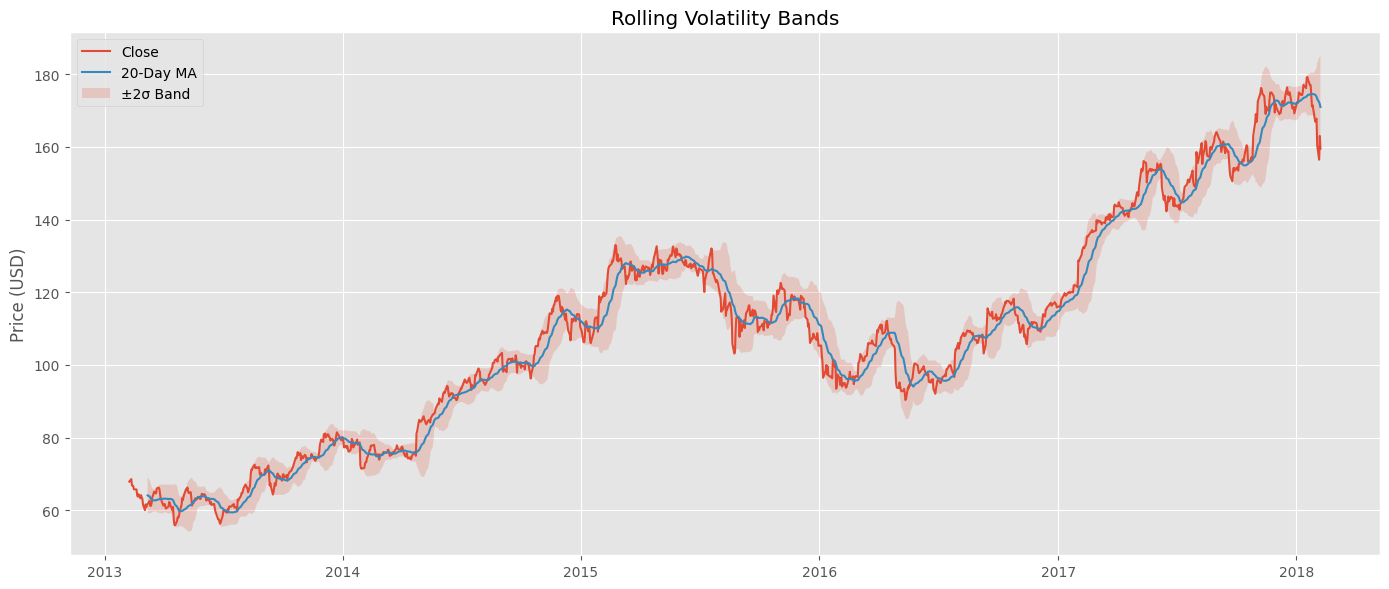

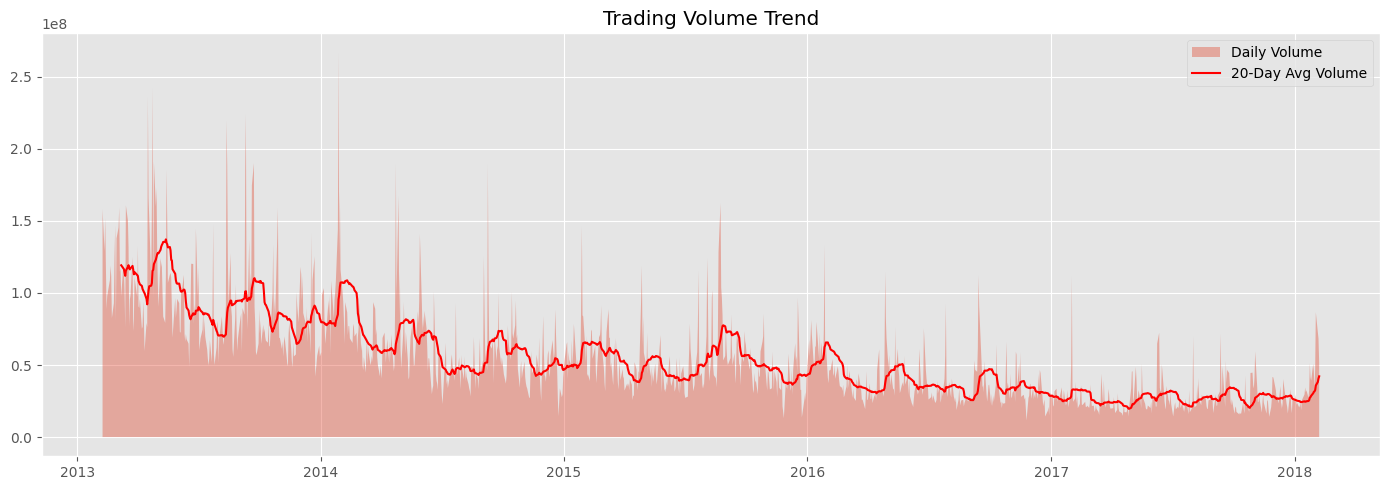

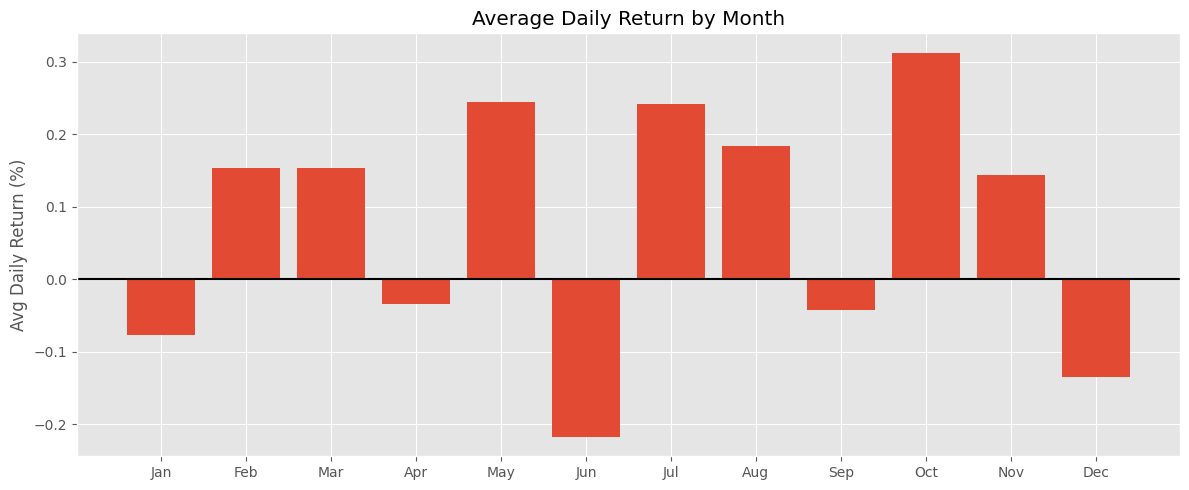

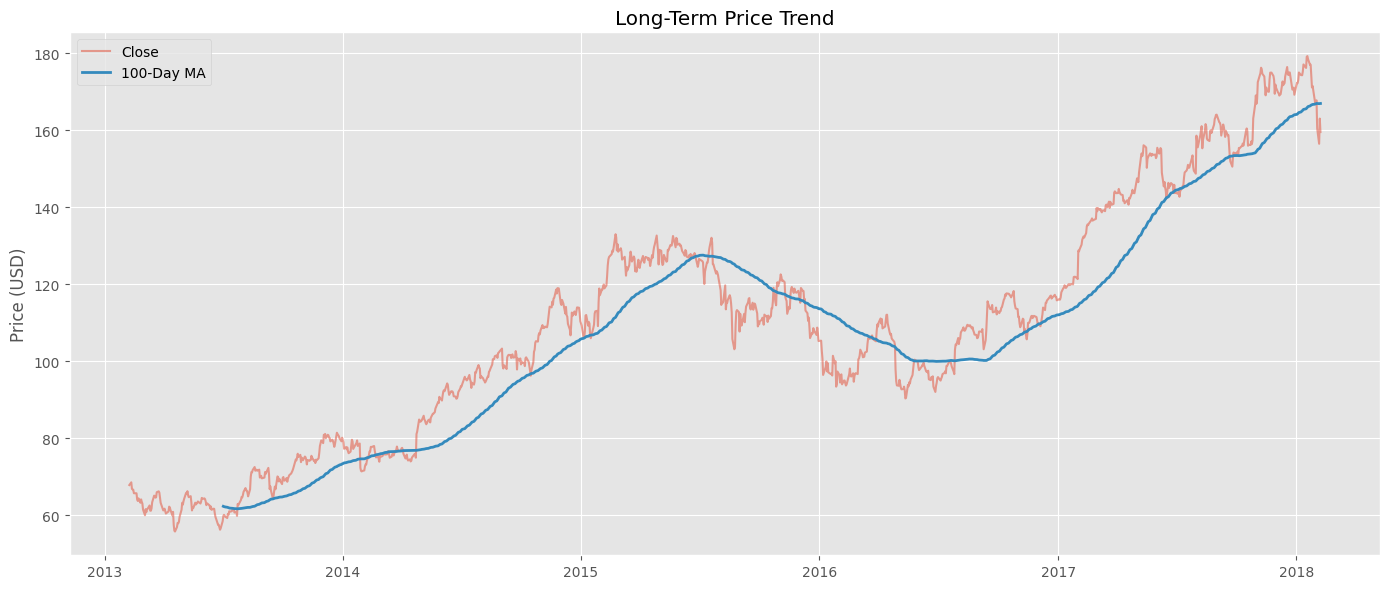


TOP 10 GAINS
      Date    Close  Daily_Return    Volume
2014-04-24  81.1099      0.081982 189978082
2017-08-01 158.5900      0.066295  21194042
2016-07-27 102.9500      0.064963  92344820
2017-02-01 128.7500      0.060981 111985040
2015-08-26 109.6900      0.057355  96774611
2015-01-28 115.3100      0.056533 146477063
2016-01-22 101.4200      0.053167  65800467
2013-07-24  62.9299      0.051360 147978789
2013-09-23  70.0914      0.049700 190021706
2013-08-13  69.9385      0.047523 219634975

TOP 10 LOSSES
      Date    Close  Daily_Return    Volume
2014-01-28  72.3571     -0.079927 266833581
2016-01-27  93.4200     -0.065707 133369674
2016-04-27  97.8200     -0.062578 114602142
2015-08-21 105.7600     -0.061163 128275471
2013-04-17  57.5428     -0.054993 236138966
2013-09-11  66.8156     -0.054444 224250866
2015-08-11 113.4900     -0.052038  97082814
2015-09-01 107.7200     -0.044697  76845860
2018-02-02 160.5000     -0.043390  86593825
2015-07-22 125.2200     -0.042294 115450607


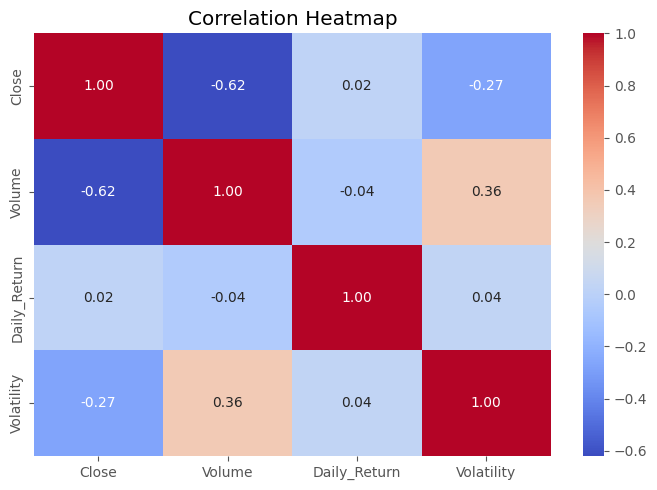


=== SUMMARY ===
count    1259.00
mean      109.07
std        30.56
min        55.79
25%        84.83
50%       109.01
75%       127.12
max       179.26

Avg daily return : 0.0786%
Avg volatility   : 1.37%
Max / Min return : 8.20% / -7.99%
End-of-data trend: Bearish


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Dataset: Kaggle S&P 500 stock data (all_stocks_5yr.csv)

import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

plt.style.use('ggplot')
FILE_NAME = 'all_stocks_5yr.csv'   # <- set your CSV path (this was undefined before)
outputs = []                       # every saved file gets tracked here


def save_plot(name):
    plt.tight_layout()
    plt.savefig(name, dpi=150)
    plt.show()
    outputs.append(name)


# 1. LOAD & CLEAN ---------------------------------------------------------
df = pd.read_csv(FILE_NAME)
df.columns = df.columns.str.strip().str.capitalize() # date->Date, open->Open, ...

# Fix: Explicitly parse Date to datetime with mixed/dayfirst handling
df['Date'] = pd.to_datetime(df['Date'], format='mixed', dayfirst=True)

df = (
    df.query("Name == 'AAPL'")
    [['Date', 'Open', 'High', 'Low', 'Close', 'Volume']]
    .dropna()
    .sort_values('Date')
    .reset_index(drop=True)
)
print(f"Records: {len(df)} | {df['Date'].min():%Y-%m-%d} -> {df['Date'].max():%Y-%m-%d}")

# 2. FEATURES -------------------------------------------------------------
close = df['Close']
df['SMA_20'] = close.rolling(20).mean()
df['SMA_50'] = close.rolling(50).mean()
df['EMA_20'] = close.ewm(span=20, adjust=False).mean()
df['Daily_Return'] = close.pct_change()
df['Volatility'] = df['Daily_Return'].rolling(20).std()
std20 = close.rolling(20).std()
df['Upper_Band'] = df['SMA_20'] + 2 * std20
df['Lower_Band'] = df['SMA_20'] - 2 * std20
df['Volume_MA'] = df['Volume'].rolling(20).mean()
df['Month'] = df['Date'].dt.month

# 3. CANDLESTICK + SMA/EMA (interactive) ----------------------------------
fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                    vertical_spacing=0.05, row_heights=[0.75, 0.25])
fig.add_trace(go.Candlestick(x=df['Date'], open=df['Open'], high=df['High'],
                             low=df['Low'], close=df['Close'],
                             name='Candlestick'), row=1, col=1)
for col, color in [('SMA_20', 'blue'), ('EMA_20', 'orange')]:
    fig.add_trace(go.Scatter(x=df['Date'], y=df[col], name=col.replace('_', ' '),
                             line=dict(color=color)), row=1, col=1)
fig.add_trace(go.Bar(x=df['Date'], y=df['Volume'], name='Volume'), row=2, col=1)
fig.update_layout(title='Apple Candlestick with SMA & EMA',
                  xaxis_rangeslider_visible=False, height=750)
fig.write_html('01_Candlestick.html')
outputs.append('01_Candlestick.html')
fig.show()

# 4. BOLLINGER (VOLATILITY) BANDS -----------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], close, label='Close')
plt.plot(df['Date'], df['SMA_20'], label='20-Day MA')
plt.fill_between(df['Date'], df['Lower_Band'], df['Upper_Band'],
                 alpha=0.2, label='±2σ Band')
plt.title('Rolling Volatility Bands')
plt.ylabel('Price (USD)')
plt.legend()
save_plot('02_Volatility_Bands.png')

# 5. VOLUME TREND (fill_between is much faster than plt.bar) --------------
plt.figure(figsize=(14, 5))
plt.fill_between(df['Date'], df['Volume'], alpha=0.4, label='Daily Volume')
plt.plot(df['Date'], df['Volume_MA'], color='red', label='20-Day Avg Volume')
plt.title('Trading Volume Trend')
plt.legend()
save_plot('03_Volume_Trends.png')

# 6. SEASONALITY ----------------------------------------------------------
monthly = df.groupby('Month')['Daily_Return'].mean().mul(100)
plt.figure(figsize=(12, 5))
plt.bar(pd.to_datetime(monthly.index, format='%m').strftime('%b'), monthly.values)
plt.axhline(0, color='black')
plt.title('Average Daily Return by Month')
plt.ylabel('Avg Daily Return (%)')
save_plot('04_Seasonal_Analysis.png')

# 7. LONG-TERM TREND ------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(df['Date'], close, alpha=0.5, label='Close')
plt.plot(df['Date'], close.rolling(100).mean(), lw=2, label='100-Day MA')
plt.title('Long-Term Price Trend')
plt.ylabel('Price (USD)')
plt.legend()
save_plot('05_Long_Term_Trend.png')

# 8. BIGGEST MOVES --------------------------------------------------------
cols = ['Date', 'Close', 'Daily_Return', 'Volume']
print("\nTOP 10 GAINS");  print(df.nlargest(10, 'Daily_Return')[cols].to_string(index=False))
print("\nTOP 10 LOSSES"); print(df.nsmallest(10, 'Daily_Return')[cols].to_string(index=False))

# 9. CORRELATION (more informative than OHLC, which is ~1.0 everywhere) ---
plt.figure(figsize=(7, 5))
sns.heatmap(df[['Close', 'Volume', 'Daily_Return', 'Volatility']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
save_plot('06_Correlation_Heatmap.png')

# 10. SUMMARY -------------------------------------------------------------
print("\n=== SUMMARY ===")
print(close.describe().round(2).to_string())
print(f"\nAvg daily return : {df['Daily_Return'].mean():.4%}")
print(f"Avg volatility   : {df['Volatility'].mean():.2%}")
print(f"Max / Min return : {df['Daily_Return'].max():.2%} / {df['Daily_Return'].min():.2%}")
last = df.iloc[-1]
print("End-of-data trend:", "Bullish" if last['SMA_20'] > last['SMA_50'] else "Bearish")

# 11. SAVE + ZIP ----------------------------------------------------------
df.to_csv('Apple_Stock_Analysis.csv', index=False)
outputs.append('Apple_Stock_Analysis.csv')

with zipfile.ZipFile('Stock_Market_Analysis_Outputs.zip', 'w') as z:
    for f in outputs:
        z.write(f)

# Colab download (skipped automatically elsewhere)
try:
    from google.colab import files
    files.download('Stock_Market_Analysis_Outputs.zip')
except ImportError:
    print("Saved: Stock_Market_Analysis_Outputs.zip")